In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import nltk
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("punkt_tab")
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
import re

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Ahesan\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Ahesan\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Ahesan\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [12]:
data=pd.read_csv("01 tripadvisor-hotel-reviews.csv")
data.info()
data.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 109 entries, 0 to 108
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Review  109 non-null    object
 1   Rating  109 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 1.8+ KB


,Review,Rating
0,nice hotel expensive parking got good deal sta...,4
1,ok nothing special charge diamond member hilto...,2
2,nice rooms not 4* experience hotel monaco seat...,3
3,"unique, great stay, wonderful time hotel monac...",5
4,"great stay great stay, went seahawk game aweso...",5


In [13]:
data["reviews_lowercase"] = [x.lower() for x in data["Review"]]
data.head()

,Review,Rating,reviews_lowercase
0,nice hotel expensive parking got good deal sta...,4,nice hotel expensive parking got good deal sta...
1,ok nothing special charge diamond member hilto...,2,ok nothing special charge diamond member hilto...
2,nice rooms not 4* experience hotel monaco seat...,3,nice rooms not 4* experience hotel monaco seat...
3,"unique, great stay, wonderful time hotel monac...",5,"unique, great stay, wonderful time hotel monac..."
4,"great stay great stay, went seahawk game aweso...",5,"great stay great stay, went seahawk game aweso..."


In [14]:
en_stopwords=set(stopwords.words("english"))
en_stopwords.remove("not")
data['review_no_stopwords']=data["reviews_lowercase"].apply(lambda x: " ".join([words for words in x.split() if words not in en_stopwords]))
data.head()

,Review,Rating,reviews_lowercase,review_no_stopwords
0,nice hotel expensive parking got good deal sta...,4,nice hotel expensive parking got good deal sta...,nice hotel expensive parking got good deal sta...
1,ok nothing special charge diamond member hilto...,2,ok nothing special charge diamond member hilto...,ok nothing special charge diamond member hilto...
2,nice rooms not 4* experience hotel monaco seat...,3,nice rooms not 4* experience hotel monaco seat...,nice rooms not 4* experience hotel monaco seat...
3,"unique, great stay, wonderful time hotel monac...",5,"unique, great stay, wonderful time hotel monac...","unique, great stay, wonderful time hotel monac..."
4,"great stay great stay, went seahawk game aweso...",5,"great stay great stay, went seahawk game aweso...","great stay great stay, went seahawk game aweso..."


In [15]:
pattern = r"[^\w\s]"
data["review_no_punct"] = data["reviews_lowercase"].apply(lambda x: re.sub(pattern,"",x))
pattern = r"[\*]"
data["review_no_punct"] = data["review_no_punct"].apply(lambda x: re.sub(pattern,"star",x))
data.head()

,Review,Rating,reviews_lowercase,review_no_stopwords,review_no_punct
0,nice hotel expensive parking got good deal sta...,4,nice hotel expensive parking got good deal sta...,nice hotel expensive parking got good deal sta...,nice hotel expensive parking got good deal sta...
1,ok nothing special charge diamond member hilto...,2,ok nothing special charge diamond member hilto...,ok nothing special charge diamond member hilto...,ok nothing special charge diamond member hilto...
2,nice rooms not 4* experience hotel monaco seat...,3,nice rooms not 4* experience hotel monaco seat...,nice rooms not 4* experience hotel monaco seat...,nice rooms not 4 experience hotel monaco seatt...
3,"unique, great stay, wonderful time hotel monac...",5,"unique, great stay, wonderful time hotel monac...","unique, great stay, wonderful time hotel monac...",unique great stay wonderful time hotel monaco ...
4,"great stay great stay, went seahawk game aweso...",5,"great stay great stay, went seahawk game aweso...","great stay great stay, went seahawk game aweso...",great stay great stay went seahawk game awesom...


In [16]:
data["tokenized"] = data["review_no_punct"].apply(lambda x: word_tokenize(x))
data.head()

,Review,Rating,reviews_lowercase,review_no_stopwords,review_no_punct,tokenized
0,nice hotel expensive parking got good deal sta...,4,nice hotel expensive parking got good deal sta...,nice hotel expensive parking got good deal sta...,nice hotel expensive parking got good deal sta...,"[nice, hotel, expensive, parking, got, good, d..."
1,ok nothing special charge diamond member hilto...,2,ok nothing special charge diamond member hilto...,ok nothing special charge diamond member hilto...,ok nothing special charge diamond member hilto...,"[ok, nothing, special, charge, diamond, member..."
2,nice rooms not 4* experience hotel monaco seat...,3,nice rooms not 4* experience hotel monaco seat...,nice rooms not 4* experience hotel monaco seat...,nice rooms not 4 experience hotel monaco seatt...,"[nice, rooms, not, 4, experience, hotel, monac..."
3,"unique, great stay, wonderful time hotel monac...",5,"unique, great stay, wonderful time hotel monac...","unique, great stay, wonderful time hotel monac...",unique great stay wonderful time hotel monaco ...,"[unique, great, stay, wonderful, time, hotel, ..."
4,"great stay great stay, went seahawk game aweso...",5,"great stay great stay, went seahawk game aweso...","great stay great stay, went seahawk game aweso...",great stay great stay went seahawk game awesom...,"[great, stay, great, stay, went, seahawk, game..."


In [17]:
ps=PorterStemmer()
lemmatizer = WordNetLemmatizer()
data["stemmed"] =data["tokenized"].apply(lambda x: [ps.stem(word) for word in x]) 
data["lemmatized"] =data["tokenized"].apply(lambda x: [lemmatizer.lemmatize(word) for word in x]) 
data.head()

,Review,Rating,reviews_lowercase,review_no_stopwords,review_no_punct,tokenized,stemmed,lemmatized
0,nice hotel expensive parking got good deal sta...,4,nice hotel expensive parking got good deal sta...,nice hotel expensive parking got good deal sta...,nice hotel expensive parking got good deal sta...,"[nice, hotel, expensive, parking, got, good, d...","[nice, hotel, expens, park, got, good, deal, s...","[nice, hotel, expensive, parking, got, good, d..."
1,ok nothing special charge diamond member hilto...,2,ok nothing special charge diamond member hilto...,ok nothing special charge diamond member hilto...,ok nothing special charge diamond member hilto...,"[ok, nothing, special, charge, diamond, member...","[ok, noth, special, charg, diamond, member, hi...","[ok, nothing, special, charge, diamond, member..."
2,nice rooms not 4* experience hotel monaco seat...,3,nice rooms not 4* experience hotel monaco seat...,nice rooms not 4* experience hotel monaco seat...,nice rooms not 4 experience hotel monaco seatt...,"[nice, rooms, not, 4, experience, hotel, monac...","[nice, room, not, 4, experi, hotel, monaco, se...","[nice, room, not, 4, experience, hotel, monaco..."
3,"unique, great stay, wonderful time hotel monac...",5,"unique, great stay, wonderful time hotel monac...","unique, great stay, wonderful time hotel monac...",unique great stay wonderful time hotel monaco ...,"[unique, great, stay, wonderful, time, hotel, ...","[uniqu, great, stay, wonder, time, hotel, mona...","[unique, great, stay, wonderful, time, hotel, ..."
4,"great stay great stay, went seahawk game aweso...",5,"great stay great stay, went seahawk game aweso...","great stay great stay, went seahawk game aweso...",great stay great stay went seahawk game awesom...,"[great, stay, great, stay, went, seahawk, game...","[great, stay, great, stay, went, seahawk, game...","[great, stay, great, stay, went, seahawk, game..."


In [18]:
lemma_token_clean = sum(data["lemmatized"],[])
lemma_token_clean

['nice',
 'hotel',
 'expensive',
 'parking',
 'got',
 'good',
 'deal',
 'stay',
 'hotel',
 'anniversary',
 'arrived',
 'late',
 'evening',
 'took',
 'advice',
 'previous',
 'review',
 'did',
 'valet',
 'parking',
 'check',
 'quick',
 'easy',
 'little',
 'disappointed',
 'nonexistent',
 'view',
 'room',
 'room',
 'clean',
 'nice',
 'size',
 'bed',
 'comfortable',
 'woke',
 'stiff',
 'neck',
 'high',
 'pillow',
 'not',
 'soundproof',
 'like',
 'heard',
 'music',
 'room',
 'night',
 'morning',
 'loud',
 'bang',
 'door',
 'opening',
 'closing',
 'hear',
 'people',
 'talking',
 'hallway',
 'maybe',
 'just',
 'noisy',
 'neighbor',
 'aveda',
 'bath',
 'product',
 'nice',
 'did',
 'not',
 'goldfish',
 'stay',
 'nice',
 'touch',
 'taken',
 'advantage',
 'staying',
 'longer',
 'location',
 'great',
 'walking',
 'distance',
 'shopping',
 'overall',
 'nice',
 'experience',
 'having',
 'pay',
 '40',
 'parking',
 'night',
 'ok',
 'nothing',
 'special',
 'charge',
 'diamond',
 'member',
 'hilton',
 '

In [19]:
stemmed_token_clean = sum(data["stemmed"],[])
stemmed_token_clean

['nice',
 'hotel',
 'expens',
 'park',
 'got',
 'good',
 'deal',
 'stay',
 'hotel',
 'anniversari',
 'arriv',
 'late',
 'even',
 'took',
 'advic',
 'previou',
 'review',
 'did',
 'valet',
 'park',
 'check',
 'quick',
 'easi',
 'littl',
 'disappoint',
 'nonexist',
 'view',
 'room',
 'room',
 'clean',
 'nice',
 'size',
 'bed',
 'comfort',
 'woke',
 'stiff',
 'neck',
 'high',
 'pillow',
 'not',
 'soundproof',
 'like',
 'heard',
 'music',
 'room',
 'night',
 'morn',
 'loud',
 'bang',
 'door',
 'open',
 'close',
 'hear',
 'peopl',
 'talk',
 'hallway',
 'mayb',
 'just',
 'noisi',
 'neighbor',
 'aveda',
 'bath',
 'product',
 'nice',
 'did',
 'not',
 'goldfish',
 'stay',
 'nice',
 'touch',
 'taken',
 'advantag',
 'stay',
 'longer',
 'locat',
 'great',
 'walk',
 'distanc',
 'shop',
 'overal',
 'nice',
 'experi',
 'have',
 'pay',
 '40',
 'park',
 'night',
 'ok',
 'noth',
 'special',
 'charg',
 'diamond',
 'member',
 'hilton',
 'decid',
 'chain',
 'shot',
 '20th',
 'anniversari',
 'seattl',
 'sta

In [20]:
unigram_lemma= pd.Series(nltk.ngrams(lemma_token_clean,1)).value_counts()
bigram_lemma= pd.Series(nltk.ngrams(lemma_token_clean,2)).value_counts()
trigram_lemma= pd.Series(nltk.ngrams(lemma_token_clean,3)).value_counts()

Text(0.5, 0, 'frequency')

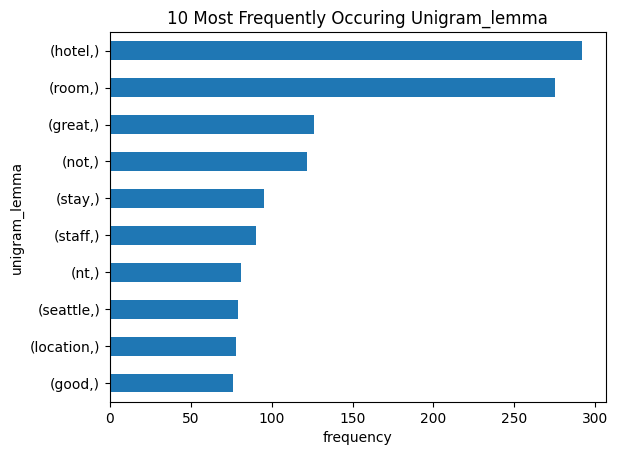

In [21]:
unigram_lemma[:10].sort_values().plot.barh()
plt.title("10 Most Frequently Occuring Unigram_lemma")
plt.ylabel("unigram_lemma")
plt.xlabel("frequency")

Text(0.5, 0, 'frequency')

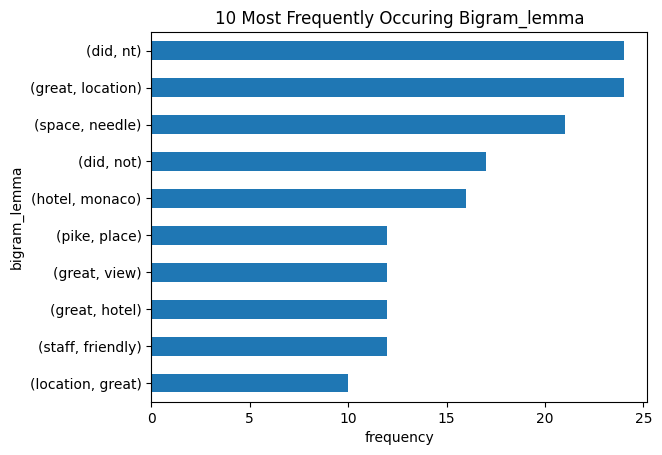

In [22]:
bigram_lemma[:10].sort_values().plot.barh()
plt.title("10 Most Frequently Occuring Bigram_lemma")
plt.ylabel("bigram_lemma")
plt.xlabel("frequency")

Text(0.5, 0, 'frequency')

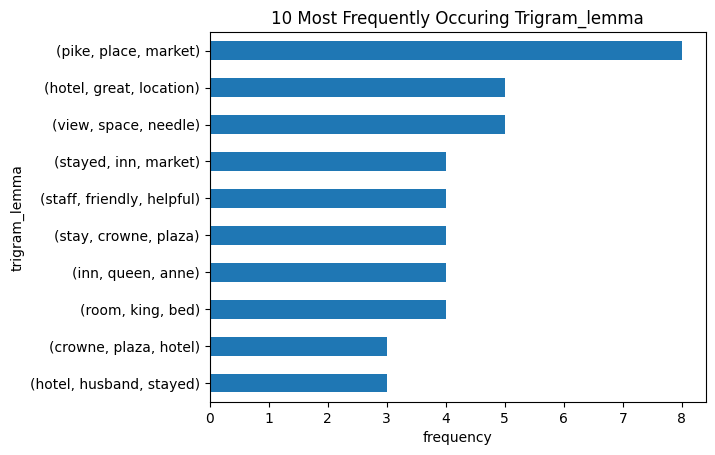

In [23]:
trigram_lemma[:10].sort_values().plot.barh()
plt.title("10 Most Frequently Occuring Trigram_lemma")
plt.ylabel("trigram_lemma")
plt.xlabel("frequency")

In [24]:
unigram_stemmed= pd.Series(nltk.ngrams(stemmed_token_clean,1)).value_counts()
bigram_stemmed = pd.Series(nltk.ngrams(stemmed_token_clean,2)).value_counts()
trigram_stemmed= pd.Series(nltk.ngrams(stemmed_token_clean,3)).value_counts()

Text(0.5, 0, 'frequency')

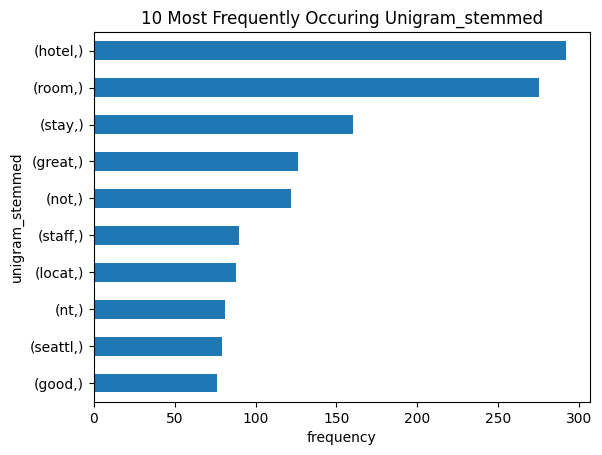

In [25]:
unigram_stemmed[:10].sort_values().plot.barh()
plt.title("10 Most Frequently Occuring Unigram_stemmed")
plt.ylabel("unigram_stemmed")
plt.xlabel("frequency")

Text(0.5, 0, 'frequency')

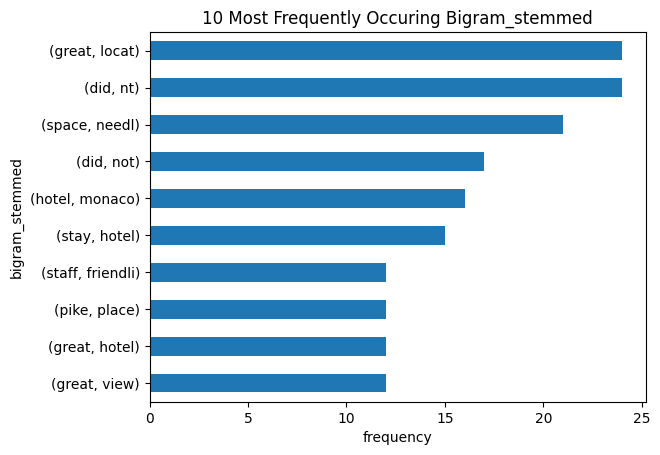

In [26]:
bigram_stemmed[:10].sort_values().plot.barh()
plt.title("10 Most Frequently Occuring Bigram_stemmed")
plt.ylabel("bigram_stemmed")
plt.xlabel("frequency")

Text(0.5, 0, 'frequency')

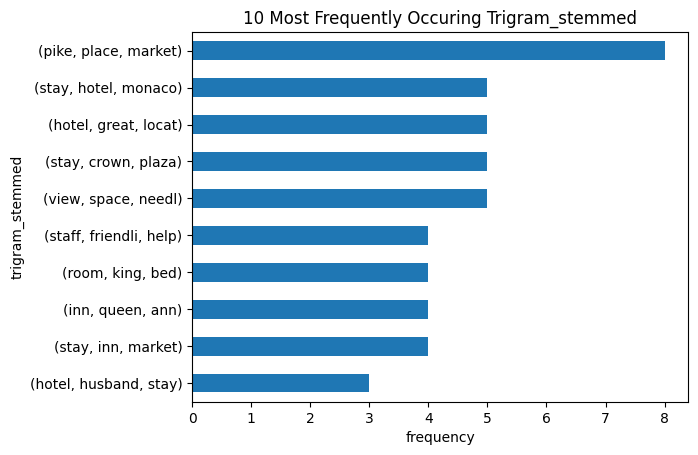

In [27]:
trigram_stemmed[:10].sort_values().plot.barh()
plt.title("10 Most Frequently Occuring Trigram_stemmed")
plt.ylabel("trigram_stemmed")
plt.xlabel("frequency")